# 12 · Matched detectors: why the zero-frequency rule over-predicted at light load

**The open question (notebook 11).** In three coupled settings, the zero-frequency rule
$$G_{\text{DC}} = \frac{d^\top\Sigma_{LR}^{-1}d}{\max_j d_j^2/\Sigma_{LR,jj}}$$
predicted the coupled detector's gain to within a factor of 1.7. At light load it over-predicted by 2.4–4.8×.

**Hypothesis H1 (fixed reference).** Every CUSUM used the reference $k = \tfrac12$. A ratio of delays equals a ratio of information rates only for detectors matched to the fault's size.

**Hypothesis H2 (short delays), formulated while analysing H1.** $G_{\text{DC}}$ is an asymptotic ratio of information rates: delay ≈ log(ARL)/KL holds only for long delays. At ARL 1000 the coupled detector alarms within a few windows, where a CUSUM's fixed overheads matter.

**Design.** To isolate these effects, all four detectors here are *oracles*: each knows the fault's direction, so no search over candidate directions blurs the comparison.

| detector | input | increment |
|---|---|---|
| PS fixed | best single slice $j^*$ (largest $d_j^2/\Sigma_{LR,jj}$) | $\operatorname{sign}(d_{j^*})\,z_{j^*} - \tfrac12$ |
| PS matched | the same slice | $\operatorname{sign}(d_{j^*})\,z_{j^*} - \lvert d_{j^*}\rvert/2$ |
| VAR fixed | VAR innovations $v$ | $v^\top\Sigma_e^{-1}\delta/\lVert\delta\rVert - \tfrac12$ |
| VAR matched | VAR innovations $v$ | $v^\top\Sigma_e^{-1}\delta/\lVert\delta\rVert - \lVert\delta\rVert/2$ |

Here $d$ and $\delta$ are the fault's measured shifts in $z$ and in $v$, and $\lVert\delta\rVert^2 = \delta^\top\Sigma_e^{-1}\delta$. The matched increments are the exact log-likelihood ratios divided by $\lvert d\rvert$ or $\lVert\delta\rVert$ (`CUSUMBank.matched`). Each detector is calibrated to ARL 1000 windows on the fault-free runs of its setting. Settings, faults and seeds are those of notebook 11.

**Two predictions from the same long-run rates, with nothing fitted:**
- **Asymptotic:** $G_{\text{DC}}$, the ratio of information rates.
- **Finite-ARL:** treat each matched detector as a Gaussian CUSUM whose signal-to-noise ratio $\mu = \sqrt{2\,\text{KL}}$ comes from its long-run rate. For the single slice, $\text{KL} = d_{j^*}^2/(2\Sigma_{LR,j^*j^*})$, the long-run variance of $z$. For the VAR, $\text{KL} = \lVert\delta\rVert^2/2$, since its innovations are white. Calibrate each to ARL 1000 and compute its delay with Siegmund's approximation (verified in notebook 01). The prediction is the ratio of the two delays.

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq

from slicead.sim import Fault, load_config, load_fault_scenarios, simulate
from slicead.detectors import CUSUMBank, StreamModel, VARModel, long_run_cov, stream_array
from slicead.eval import calibrate_threshold, first_alarms, summarize_delays

SEED = 20261022                       # same seeds as notebooks 05-11
OUT = Path("../results/12_matched_reference")
OUT.mkdir(parents=True, exist_ok=True)
REPORT = Path("../report")
for sub in ("figures", "tables"):                      # report/ is not in the public repository
    (REPORT / sub).mkdir(parents=True, exist_ok=True)

def save_fig(fig, name):
    fig.savefig(OUT / f"{name}.png", bbox_inches="tight")
    fig.savefig(REPORT / "figures" / f"12_{name}.pdf", bbox_inches="tight")

def save_tex_table(df, name, column_format):
    (REPORT / "tables" / f"12_{name}.tex").write_text(
        df.to_latex(index=False, escape=False, column_format=column_format), encoding="utf-8")

def save_tex_numbers(numbers, name="numbers"):
    lines = [f"\\newcommand{{\\{k}}}{{{v}}}" for k, v in numbers.items()]
    (REPORT / "tables" / f"12_{name}.tex").write_text("\n".join(lines) + "\n", encoding="utf-8")

SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "lines.linewidth": 2, "lines.markersize": 6, "font.size": 10,
    "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 150,
})

SETTINGS = ["default", "high_load", "new_mix", "light_load", "control"]
NICE_SET = {"default": "default", "high_load": "high load", "new_mix": "new mix", "light_load": "light load",
            "control": "control"}
COLOR = {"default": BLUE, "high_load": ORANGE, "new_mix": AQUA, "light_load": YELLOW, "control": MUTED}
LAT = [(s, "latency_ms") for s in ["eMBB", "URLLC", "mMTC"]]
TARGET_ARL, CHANGE_S, HORIZON_W, WINDOW_S = 1000, 10.0, 300, 0.1
STRENGTHS = [0.03, 0.1, 0.25, 0.5, 1.0]
SCEN = load_fault_scenarios("../configs/faults.yaml", start_s=CHANGE_S)
ALL = list(SCEN)
LOCAL = ["urllc_surge", "mmtc_storm", "urllc_weight_misconfig"]
NICE = {"urllc_surge": "URLLC surge", "mmtc_storm": "mMTC storm", "urllc_weight_misconfig": "URLLC weight misconfig."}
DETS = ["PS fixed", "PS matched", "VAR fixed", "VAR matched"]

def siegmund(D, h):
    """Siegmund's ARL / delay of a CUSUM with N(D, 1) increments and threshold h (notebook 01)."""
    b = h + 1.166
    return b if abs(D) < 1e-9 else (np.expm1(-2 * D * b) + 2 * D * b) / (2 * D**2)

def predicted_delay_s(kl, arl=TARGET_ARL):
    """Finite-ARL delay of a matched Gaussian CUSUM with signal-to-noise mu = sqrt(2 KL), in seconds."""
    mu = np.sqrt(2 * kl)
    with np.errstate(over="ignore"):
        f = lambda h: siegmund(-mu / 2, h) - arl
        h = 0.0 if f(0.0) >= 0 else brentq(f, 0.0, 1e4)     # very strong faults: any excursion alarms
        return WINDOW_S * max(1.0, siegmund(mu / 2, h))

## 1. Four oracle detectors in five settings

For each setting, `run_setting` does the following:
- fits the AR(1) and VAR models on training runs;
- estimates $\Sigma_{LR}$ (Bartlett, $L = 50$);
- runs the three local faults at five strengths and measures each fault's shifts $d$ (in $z$) and $\delta$ (in $v$), as post-fault minus pre-fault means;
- builds and calibrates the four oracle detectors for that fault.

Where the calibration cannot reach ARL 1000 (a matched reference so large that the fault-free statistic hardly ever leaves 0), the achieved ARL is recorded, and the case is excluded from the comparisons below.

In [2]:
def run_setting(name):
    t0 = time.time()
    cfg = load_config(f"../configs/sim_{name}.yaml")
    Xtr = stream_array(simulate(cfg, n_windows=3000, n_runs=8, seed=SEED), LAT)
    Xcal = stream_array(simulate(cfg, n_windows=3000, n_runs=32, seed=SEED + 1), LAT)
    ar1 = StreamModel().fit(Xtr)
    var = VARModel(max_p=30).fit(Xtr)
    Zcal, Vcal = ar1.whiten(Xcal), var.whiten(Xcal)
    SLR = long_run_cov(ar1.whiten(Xtr), 50)
    rows = []
    for scen in LOCAL:
        i = ALL.index(scen)
        for j, s in enumerate(STRENGTHS):
            res = simulate(cfg, n_windows=400, n_runs=32, seed=SEED + 100 + 10 * i + j,
                           faults=[Fault(f.kind, f.start_s, f.factor ** s, f.slice, f.ramp_s) for f in SCEN[scen]])
            X = stream_array(res, LAT)
            Z, V = ar1.whiten(X), var.whiten(X)
            nu = res.fault_window
            d = Z[:, nu + 20:].mean(axis=(0, 1)) - Z[:, :nu].mean(axis=(0, 1))
            delta = V[:, nu + 20:].mean(axis=(0, 1)) - V[:, :nu].mean(axis=(0, 1))
            rates = d**2 / np.diag(SLR)
            js = int(np.argmax(rates))
            sg = np.sign(d[js])
            dets = {"PS fixed": (CUSUMBank([[sg]], [[1.0]]), Zcal[:, :, [js]], Z[:, :, [js]]),
                    "PS matched": (CUSUMBank.matched([d[js]], [[1.0]]), Zcal[:, :, [js]], Z[:, :, [js]]),
                    "VAR fixed": (CUSUMBank([delta], var.Sigma_e), Vcal, V),
                    "VAR matched": (CUSUMBank.matched(delta, var.Sigma_e), Vcal, V)}
            row = dict(setting=name, scenario=scen, strength=s, best_slice=js,
                       KL_ps=rates[js] / 2, KL_dc=(d @ np.linalg.solve(SLR, d)) / 2,
                       KL_var=(delta @ np.linalg.solve(var.Sigma_e, delta)) / 2)
            for dn, (det, Zc, Zt) in dets.items():
                h, arl = calibrate_threshold(det, Zc, TARGET_ARL)
                t, _ = first_alarms(det, Zt, h)
                out = summarize_delays(t, nu, HORIZON_W, WINDOW_S)
                row.update({f"{dn} delay": out["delay_mean_s"], f"{dn} found": out["detected"], f"{dn} arl": arl})
            rows.append(row)
    print(f"{name}: {time.time() - t0:.0f} s")
    return rows

res = pd.DataFrame([r for n in SETTINGS for r in run_setting(n)])
res["arl_ok"] = np.all([np.abs(np.log(res[f"{d} arl"] / TARGET_ARL)) < 0.05 for d in DETS], axis=0)
res["gain_fixed"] = res["PS fixed delay"] / res["VAR fixed delay"]
res["gain_matched"] = res["PS matched delay"] / res["VAR matched delay"]
res["G_dc"] = res.KL_dc / res.KL_ps
res["pred_ps_s"] = [predicted_delay_s(k) for k in res.KL_ps]
res["pred_var_s"] = [predicted_delay_s(k) for k in res.KL_var]
res["G_finite"] = res.pred_ps_s / res.pred_var_s
res.to_csv(OUT / "oracle.csv", index=False)
print("cases where calibration could not reach ARL 1000:", int((~res.arl_ok).sum()), "of", len(res))

default: 193 s


high_load: 198 s


new_mix: 195 s


light_load: 189 s


control: 192 s


cases where calibration could not reach ARL 1000: 38 of 75


## 2. Test of H1: does matching the reference fix light load?

For each fault we apply notebook 11's rule to the oracle detectors: take the weakest strength at which the fixed-reference single-slice detector finds at least 80% of faults. (Notebook 11 applied it to the three-slice per-slice CUSUM, so the chosen strength can differ.) There we compare the fixed and matched oracle gains with $G_{\text{DC}}$.

In [3]:
rows = []
for (n, scen), g in res.groupby(["setting", "scenario"], sort=False):
    g = g[g["PS fixed found"] >= 0.8]
    r = g.loc[g.strength.idxmin()]
    rows.append(dict(setting=n, scenario=scen, strength=r.strength, gain_fixed=r.gain_fixed,
                     gain_matched=r.gain_matched, G_dc=r.G_dc, ratio_fixed=r.gain_fixed / r.G_dc,
                     ratio_matched=r.gain_matched / r.G_dc, arl_ok=r.arl_ok))
H1 = pd.DataFrame(rows)
H1.to_csv(OUT / "h1_fixed_vs_matched.csv", index=False)
H1.round(2)

,setting,scenario,strength,gain_fixed,gain_matched,G_dc,ratio_fixed,ratio_matched,arl_ok
0,default,urllc_surge,0.10,18.63,10.48,17.98,1.04,0.58,True
1,default,mmtc_storm,0.10,16.50,10.39,23.85,0.69,0.44,True
2,default,urllc_weight_misconfig,0.10,21.91,29.68,30.40,0.72,0.98,True
3,high_load,urllc_surge,0.10,19.18,14.12,12.53,1.53,1.13,True
4,high_load,mmtc_storm,0.10,23.25,11.39,15.43,1.51,0.74,True
5,high_load,urllc_weight_misconfig,0.10,13.35,17.41,24.36,0.55,0.71,True
6,new_mix,urllc_surge,0.10,24.54,20.47,20.96,1.17,0.98,True
7,new_mix,mmtc_storm,0.10,41.70,38.03,15.84,2.63,2.40,True
8,new_mix,urllc_weight_misconfig,0.10,38.32,41.41,37.05,1.03,1.12,True
9,light_load,urllc_surge,0.03,3.85,6.06,11.78,0.33,0.51,True


**What Section 2 shows: H1 is refuted, and notebook 11's agreement was partly luck**

- **Matching the reference does not fix light load.** Measured/predicted moves from 0.29–0.41 (fixed $k$) to only 0.23–0.51 (matched $k$). The rule still over-predicts by 2–4×.
- **Matching the reference moves gains in both directions elsewhere.** For example, the default URLLC surge goes from 18.6× to 10.5×, and the default weight misconfiguration from 21.9× to 29.7×. A fixed $k = \tfrac12$ handicaps whichever detector's drift lies further from $\tfrac12$, so a fixed-$k$ gain is partly a statement about tuning.
- **So notebook 11's close agreement in the default and high-load settings partly reflected the per-slice detector's handicap.** With matched detectors, the asymptotic rule over-predicts in those settings too: measured/predicted is 0.44–0.98 in the default, against 0.69–1.04 with fixed $k$.

## 3. Test of H2: the same theory at the actual ARL

We use every case where all four detectors reached ARL 1000 and the matched per-slice detector finds at least 80% of faults. For each such case we compare:
- each matched detector's measured delay with its finite-ARL prediction;
- the matched gain with the asymptotic $G_{\text{DC}}$ and with the finite-ARL prediction $G_{\text{fin}}$.

Cases where the VAR detector alarms in the first one or two windows (delay ≤ 0.15 s) agree almost by construction, so we also report the comparison without them.

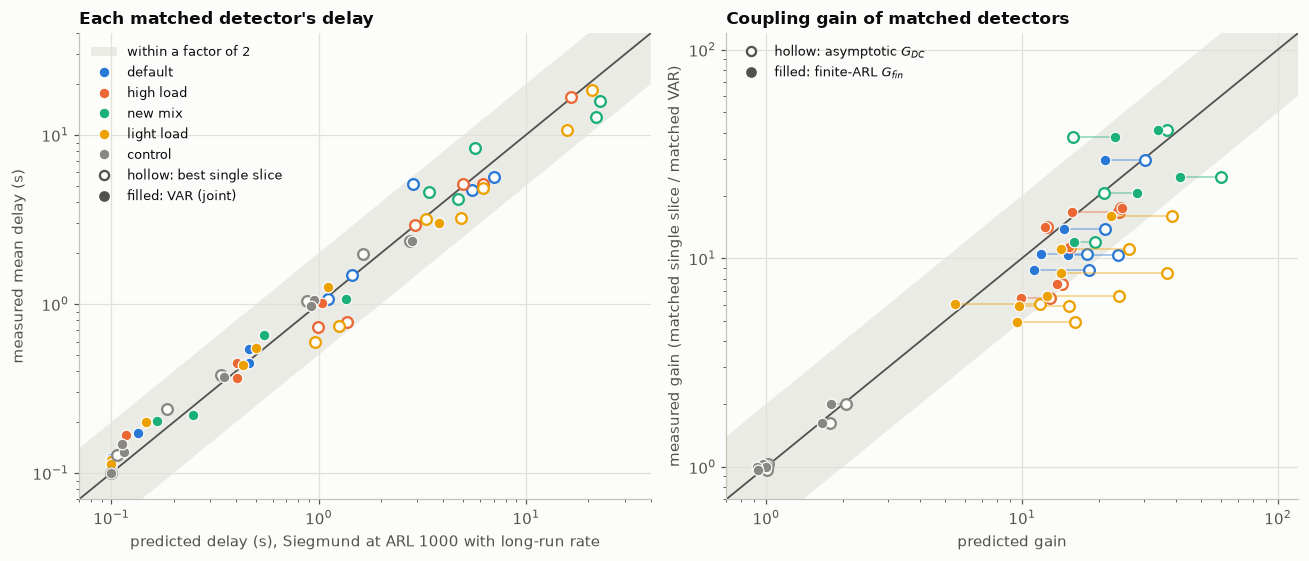

measured / predicted delay, by detector:
           single slice         VAR      
                    min   max   min   max
setting                                  
default            0.81  1.80  0.97  1.29
high_load          0.57  1.03  0.90  1.42
new_mix            0.58  1.46  0.78  1.23
light_load         0.59  0.97  0.80  1.35
control            0.86  1.29  0.84  1.32


,cases,prediction,n,median,lo,hi,within_2
0,all,asymptotic G_DC,30,0.68,0.23,2.40,20
1,all,finite-ARL G_fin,30,0.83,0.52,1.65,30
2,VAR delay > 0.15 s,asymptotic G_DC,20,0.70,0.23,2.40,13
3,VAR delay > 0.15 s,finite-ARL G_fin,20,0.83,0.59,1.65,20
4,"coupled settings, VAR delay > 0.15 s",asymptotic G_DC,16,0.60,0.23,2.40,9
5,"coupled settings, VAR delay > 0.15 s",finite-ARL G_fin,16,0.75,0.59,1.65,16


In [4]:
use = res[res.arl_ok & (res["PS matched found"] >= 0.8)].copy()
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
ax = axes[0]
lo, hi = 0.07, 40
xs = np.array([lo, hi])
ax.fill_between(xs, xs / 2, xs * 2, color=GRID, alpha=0.6, lw=0, label="within a factor of 2")
ax.plot(xs, xs, color=INK2, lw=1.2)
for n in SETTINGS:
    g = use[use.setting == n]
    ax.plot(g.pred_ps_s, g["PS matched delay"], "o", color=COLOR[n], mfc=SURFACE, mew=1.5, ms=7)
    ax.plot(g.pred_var_s, g["VAR matched delay"], "o", color=COLOR[n], ms=7, mec=SURFACE, mew=0.8, label=NICE_SET[n])
ax.plot([], [], "o", color=INK2, mfc=SURFACE, mew=1.5, label="hollow: best single slice")
ax.plot([], [], "o", color=INK2, label="filled: VAR (joint)")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
ax.set_xlabel("predicted delay (s), Siegmund at ARL 1000 with long-run rate")
ax.set_ylabel("measured mean delay (s)")
ax.set_title("Each matched detector's delay")
ax.legend(loc="upper left", fontsize=8.5)

ax = axes[1]
lo, hi = 0.7, 120
xs = np.array([lo, hi])
ax.fill_between(xs, xs / 2, xs * 2, color=GRID, alpha=0.6, lw=0)
ax.plot(xs, xs, color=INK2, lw=1.2)
for n in SETTINGS:
    g = use[use.setting == n]
    for _, r in g.iterrows():
        ax.plot([r.G_dc, r.G_finite], [r.gain_matched] * 2, color=COLOR[n], lw=1, alpha=0.5)
    ax.plot(g.G_dc, g.gain_matched, "o", color=COLOR[n], mfc=SURFACE, mew=1.5, ms=7)
    ax.plot(g.G_finite, g.gain_matched, "o", color=COLOR[n], ms=7, mec=SURFACE, mew=0.8)
ax.plot([], [], "o", color=INK2, mfc=SURFACE, mew=1.5, label=r"hollow: asymptotic $G_{DC}$")
ax.plot([], [], "o", color=INK2, label=r"filled: finite-ARL $G_{fin}$")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
ax.set_xlabel("predicted gain")
ax.set_ylabel("measured gain (matched single slice / matched VAR)")
ax.set_title("Coupling gain of matched detectors")
ax.legend(loc="upper left", fontsize=8.5)
fig.tight_layout()
save_fig(fig, "fig1_finite_arl")
plt.show()

def summary(g, label):
    out = []
    for name, col in [("asymptotic G_DC", "G_dc"), ("finite-ARL G_fin", "G_finite")]:
        q = g.gain_matched / g[col]
        out.append(dict(cases=label, prediction=name, n=len(q), median=q.median(), lo=q.min(), hi=q.max(),
                        within_2=int(((q > 0.5) & (q < 2)).sum())))
    return out

S = pd.DataFrame(summary(use, "all") + summary(use[use["VAR matched delay"] > 0.15], "VAR delay > 0.15 s")
                 + summary(use[(use["VAR matched delay"] > 0.15) & (use.setting != "control")],
                           "coupled settings, VAR delay > 0.15 s"))
S.to_csv(OUT / "prediction_summary.csv", index=False)
dr = pd.DataFrame({"setting": use.setting, "single slice": use["PS matched delay"] / use.pred_ps_s,
                   "VAR": use["VAR matched delay"] / use.pred_var_s}).groupby("setting", sort=False).agg(["min", "max"])
print("measured / predicted delay, by detector:")
print(dr.round(2))
S.round(2)

**What Section 3 shows: H2 is supported. The long-run rates are right; the asymptotic ratio is not.**

- **The finite-ARL prediction is within a factor of 2 in all 30 cases** (median 0.83, range 0.52–1.65), against 20 of 30 for the asymptotic $G_{\text{DC}}$ (median 0.68).
- **The difference grows where it matters.** In the coupled settings without floor cases, the finite-ARL prediction holds in 16 of 16 cases and the asymptotic one in 9 of 16.
- **Light load is explained.** Its gains are predicted as well as any other setting's.
- **Each matched detector's own delay is predicted to within a factor of about 1.8.** The ratio is 0.57–1.80 for the single slice and 0.78–1.42 for the VAR. Two small biases both shrink the gain, which explains the median of 0.83:
  - the single slice is often *faster* than predicted (down to 0.57 in high load and light load), because a detector that alarms within seconds accumulates less than the full long-run variance;
  - the VAR detector is on average slightly slower than predicted.
- **Why the asymptotic ratio fails.** Delay ≈ log(ARL)/KL describes long delays. At ARL 1000 a CUSUM pays an overhead of a few windows (the overshoot and the climb from 0). That overhead is a large share of the coupled detector's 1–6-window delay, and a small share of the single slice's 30–80 windows. The realised gain is therefore compressed below the ratio of rates, and most strongly where faults are most visible: light load, where every delay is short.

In [5]:
# Export tables and key numbers for report/main.tex
f1 = lambda v: "--" if pd.isna(v) else f"{v:.1f}"
f2 = lambda v: "--" if pd.isna(v) else f"{v:.2f}"
t = H1[["setting", "scenario", "strength", "gain_fixed", "gain_matched", "G_dc", "ratio_fixed", "ratio_matched"]].copy()
t["setting"] = [NICE_SET[v] if i == 0 or v != t.setting.iloc[i - 1] else "" for i, v in enumerate(t.setting)]
t["scenario"] = t.scenario.map(NICE)
t["strength"] = t.strength.map(lambda v: f"{v:g}")
for c in ["gain_fixed", "gain_matched", "G_dc"]:
    t[c] = t[c].map(f1)
for c in ["ratio_fixed", "ratio_matched"]:
    t[c] = t[c].map(f2)
t.columns = ["setting", "fault", "$s$", "gain, fixed $k$", "gain, matched $k$", "$G_{\\mathrm{DC}}$",
             "fixed / $G_{\\mathrm{DC}}$", "matched / $G_{\\mathrm{DC}}$"]
save_tex_table(t, "h1", "lllrrrrr")

t = S.copy()
t["cases"] = [v.replace(">", "$>$") if i == 0 or v != t.cases.iloc[i - 1] else "" for i, v in enumerate(t.cases)]
t["prediction"] = t.prediction.map({"asymptotic G_DC": "asymptotic $G_{\\mathrm{DC}}$",
                                    "finite-ARL G_fin": "finite-ARL $G_{\\mathrm{fin}}$"})
for c in ["median", "lo", "hi"]:
    t[c] = t[c].map(f2)
t["within_2"] = [f"{w}/{n}" for w, n in zip(S.within_2, S.n)]
t = t[["cases", "prediction", "median", "lo", "hi", "within_2"]]
t.columns = ["cases", "prediction", "median", "min", "max", "within $\\times 2$"]
save_tex_table(t, "summary", "llrrrr")

light = H1[H1.setting == "light_load"]
Sa = S.set_index(["cases", "prediction"])
save_tex_numbers({
    "MrLightFixedMin": f2(light.ratio_fixed.min()), "MrLightFixedMax": f2(light.ratio_fixed.max()),
    "MrLightMatchedMin": f2(light.ratio_matched.min()), "MrLightMatchedMax": f2(light.ratio_matched.max()),
    "MrN": f"{len(use)}",
    "MrDcMedian": f2(Sa.loc[("all", "asymptotic G_DC"), "median"]),
    "MrDcWithin": f"{Sa.loc[('all', 'asymptotic G_DC'), 'within_2']}",
    "MrFinMedian": f2(Sa.loc[("all", "finite-ARL G_fin"), "median"]),
    "MrFinLo": f2(Sa.loc[("all", "finite-ARL G_fin"), "lo"]), "MrFinHi": f2(Sa.loc[("all", "finite-ARL G_fin"), "hi"]),
    "MrFinWithin": f"{Sa.loc[('all', 'finite-ARL G_fin'), 'within_2']}",
    "MrCoupledN": f"{Sa.loc[('coupled settings, VAR delay > 0.15 s', 'finite-ARL G_fin'), 'n']}",
    "MrCoupledFinWithin": f"{Sa.loc[('coupled settings, VAR delay > 0.15 s', 'finite-ARL G_fin'), 'within_2']}",
    "MrCoupledDcWithin": f"{Sa.loc[('coupled settings, VAR delay > 0.15 s', 'asymptotic G_DC'), 'within_2']}",
})
print("exported:", sorted(p.name for p in (REPORT / "tables").glob("12_*")))

exported: ['12_h1.tex', '12_numbers.tex', '12_summary.tex']


## Summary

- **H1 (fixed reference) is refuted.** Matching each CUSUM to the fault's size leaves the light-load over-prediction in place (measured/predicted 0.23–0.51).
- **H2 (short delays) is supported.**
  - The zero-frequency information rates are the right inputs: $d_{j}^2/(2\Sigma_{LR,jj})$ for the best single slice, and $\lVert\delta\rVert^2/2$ for the jointly whitened slices.
  - But they must be turned into delays with standard CUSUM theory at the actual ARL, not compared as a ratio. Done that way, the same theory predicts the matched detectors' gain to within a factor of 2 in all 30 cases across five settings, light load included.
- **Corrections to earlier claims:**
  - the asymptotic rule $1/(1-R^2_{\text{DC}})$ is an *upper limit* that the realised gain approaches only as delays grow, not a prediction at ARL 1000;
  - notebook 11's agreement in three settings came partly from the fixed-$k$ handicap of its per-slice baseline.
- **Caveats:**
  - these are oracle detectors that know the fault's direction and size, and the shifts are measured on the same runs;
  - practical detectors also pay for not knowing the fault (fixed $k$, a search over candidates);
  - one ARL (1000 windows), simulation only.
- **A sharp next test follows from H2.** As the ARL grows, delays lengthen and the matched gain should rise towards $G_{\text{DC}}$. For example, it should be visibly closer at ARL 10 000 than at 100. Since this follows from the theory without new parameters, it is a good pre-registered check.